# Part 1: Pre-processing, Language Models and Perplexity
In this part we build one bigram language model for positive reviews and one for negative reviews,
then use them as a classifier (the model that finds the review less surprising wins).

In [164]:
import random
from datasets import load_dataset
import math

# loading dataset and splitting

In [165]:
random.seed(42) # define a seed that will work on
raw = load_dataset("stanfordnlp/imdb") #Load data
train_pos = []
train_neg = []
test_pos = []
test_neg = []

for row in raw["train"]:    #extractsamples  train class
    if row["label"] == 1:
        train_pos.append(row["text"])
    else:
        train_neg.append(row["text"])

random.shuffle(train_pos)
random.shuffle(train_neg)
train_pos = train_pos[:2500] #Pick train samples after shuffling
train_neg = train_neg[:2500]

 #do the same procedure for the test
for row in raw["test"]:
    if row["label"] == 1:
        test_pos.append(row["text"])
    else:
        test_neg.append(row["text"])
random.shuffle(test_pos)
random.shuffle(test_neg)

test_pos = test_pos[:500]
test_neg = test_neg[:500] #pick 1000 test/ 500 pos/500 neg


print("train pos:", len(train_pos))
print("train neg:", len(train_neg))
print("test pos:", len(test_pos))
print("test neg:", len(test_neg))

train pos: 2500
train neg: 2500
test pos: 500
test neg: 500


In [166]:
print(train_pos[0][:600])
print("-----")
print(train_neg[0][:600])
print("-----")
print(train_neg[1][:600])

A friend lent me this DVD, which he got from the director at a festival, I think. I went in warned that some of the technical aspects of the movie were a bit shaky and that the writing was good but not great. So maybe that colored my judgment but I have to admit that I liked this movie.<br /><br />The standouts where the actors. Youssef Kerkor was really good as Ernie, the main character, kind of pathetic in a likable way. Adam Jones (who also directed) and Justin Lane were excellent as the roommates who drive Ernie mad. The Bill character (Justin Lane), who spends a lot of the film dressed li
-----
You MUST be kidding!!!! Let's entertain the possibility that Parker Posey is really an actress, and not just some entry in the "quirk of the month club" of actors. Really, unless this is meant to be a tongue-in-cheek satire on David Mamet-- terse, confusing dialog delivered alternately in machine gun rapidity or monotone (think Ben Stein) blandness--or a flat out dry comedy; this film has g

## what we noticed in the raw reviews
- the text has `<br /><br />` html tags in it (if we leave them, "br" becomes a fake word)
- there is mixed capitalisation ("Great" vs "great") and a lot of punctuation
- `!` and `?` carry emotion ("!!!!"), so we keep them as their own tokens
- everything else (dots, quotes, dashes...) is just noise for counting, so we turn it into a space

In [167]:
def normalize_review(review):
    # characters we keep exactly as they are
    KEEP_CHARS = "abcdefghijklmnopqrstuvwxyz0123456789'"
    # emotion symbols we keep, but as separate tokens
    EMOTION_MARKS = "!?"
    #  remove the HTML line-break tag first, so "br" never becomes a fake word
    review = review.replace("<br />", " ")
    #  lowercase so "Great" and "great" share one count
    review = review.lower()
    #  rebuild the text one character at a time
    cleaned = ""
    for char in review:
        if char in KEEP_CHARS:
            cleaned = cleaned + char
        elif char in EMOTION_MARKS:   # i need my emotion marks to show like questioning or excitement
            cleaned = cleaned + " " + char + " "
        else:  #no need to puncutation to  take them as counts
            cleaned = cleaned + " "

    return cleaned

## tokenizing
we cut the cleaned text into words and pad each review with `<s>` (start) and `</s>` (end),
so the model knows how a review starts and how it ends.

In [168]:
def tokenize_review(review):
    cleaned = normalize_review(review)    # clean the text first
    words = cleaned.split()               # cut into a list of words
    tokens = ["<s>"] + words + ["</s>"]   # add start and end markers
    return tokens

# quick check on a small made-up review
print(tokenize_review("Great movie!<br />Don't miss it."))

['<s>', 'great', 'movie', '!', "don't", 'miss', 'it', '</s>']


In [169]:
train_pos_tokens = []
for review in train_pos:
    train_pos_tokens.append(tokenize_review(review))

train_neg_tokens = []
for review in train_neg:
    train_neg_tokens.append(tokenize_review(review))

test_pos_tokens = []
for review in test_pos:
    test_pos_tokens.append(tokenize_review(review))

test_neg_tokens = []
for review in test_neg:
    test_neg_tokens.append(tokenize_review(review))

print("train pos:", len(train_pos_tokens))
print("train neg:", len(train_neg_tokens))
print("test pos:", len(test_pos_tokens))
print("test neg:", len(test_neg_tokens))

print()
print("first 15 tokens of the first positive review:")
print(train_pos_tokens[0][:15])
print("last 5 tokens:")
print(train_pos_tokens[0][-5:])

train pos: 2500
train neg: 2500
test pos: 500
test neg: 500

first 15 tokens of the first positive review:
['<s>', 'a', 'friend', 'lent', 'me', 'this', 'dvd', 'which', 'he', 'got', 'from', 'the', 'director', 'at', 'a']
last 5 tokens:
['adam', 'jones', 'and', 'crew', '</s>']


## counting the bigrams
for every review we slide over the tokens two at a time.
- `bigram_counts[(a, b)]` = how many times word `b` came right after word `a`
- `context_counts[a]` = how many times `a` appeared as the first word of a pair (we divide by this later)

we do it once for the positive reviews and once for the negative reviews.

In [170]:
def count_bigrams(token_lists):
    bigram_counts = {}
    context_counts = {}

    for tokens in token_lists:
        for i in range(len(tokens) - 1):      # stop one early because we look at i and i+1
            prev_word = tokens[i]
            word = tokens[i + 1]
            pair = (prev_word, word)
            bigram_counts[pair] = bigram_counts.get(pair, 0) + 1            # count this pair
            context_counts[prev_word] = context_counts.get(prev_word, 0) + 1  # count the first word

    return bigram_counts, context_counts


pos_bigrams, pos_contexts = count_bigrams(train_pos_tokens)
neg_bigrams, neg_contexts = count_bigrams(train_neg_tokens)

print("positive: different bigrams =", len(pos_bigrams))
print("negative: different bigrams =", len(neg_bigrams))

# sanity check: some phrases should lean towards one class
print()
print("how often does 'not good' appear?")
print("  in positive reviews:", pos_bigrams.get(("not", "good"), 0))
print("  in negative reviews:", neg_bigrams.get(("not", "good"), 0))
print("how often does 'a must' appear?")
print("  in positive reviews:", pos_bigrams.get(("a", "must"), 0))
print("  in negative reviews:", neg_bigrams.get(("a", "must"), 0))

positive: different bigrams = 254924
negative: different bigrams = 244247

how often does 'not good' appear?
  in positive reviews: 6
  in negative reviews: 20
how often does 'a must' appear?
  in positive reviews: 77
  in negative reviews: 5


## vocabulary size
Laplace (add-1) smoothing needs `V`, the number of different words. we take it from the training data of both classes.

In [171]:
vocab = set()

for tokens in train_pos_tokens:
    for word in tokens:
        vocab.add(word) # see all vocab in train pos

for tokens in train_neg_tokens:
    for word in tokens:
        vocab.add(word) #see all vocab in train neg

V = len(vocab)
print("vocabulary size V:", V)

vocabulary size V: 42587


## bigram probability with add-1 smoothing
$$P(word \mid prev) = \frac{count(prev, word) + 1}{count(prev) + V}$$
the +1 and +V make sure a bigram we never saw still gets a small probability instead of 0
(a single 0 would make the whole review's probability 0).

In [172]:
def bigram_prob(prev_word, word, bigrams, contexts, V):
    pair_count = bigrams.get((prev_word, word), 0)    # 0 if we never saw this pair
    context_count = contexts.get(prev_word, 0)        # 0 if we never saw this first word
    return (pair_count + 1) / (context_count + V)

### checking it on a tiny example
with only 3 mini reviews we can do the math by hand, and the probabilities after one word must add up to 1.

In [173]:
toy = [
    ["<s>", "great", "movie", "</s>"],
    ["<s>", "great", "acting", "</s>"],
    ["<s>", "boring", "movie", "</s>"],
]
toy_bigrams, toy_contexts = count_bigrams(toy)
toy_V = 6    # <s>, great, boring, movie, acting, </s>

print("P(great | <s>)     =", bigram_prob("<s>", "great", toy_bigrams, toy_contexts, toy_V))
print("P(movie | boring)  =", bigram_prob("boring", "movie", toy_bigrams, toy_contexts, toy_V))
print("P(acting | boring) =", bigram_prob("boring", "acting", toy_bigrams, toy_contexts, toy_V))

# the probabilities after 'great' must add up to 1
total = 0
for w in ["<s>", "great", "boring", "movie", "acting", "</s>"]:
    total = total + bigram_prob("great", w, toy_bigrams, toy_contexts, toy_V)
print("sum after 'great'  =", total)

print()
print("positive model, P(good | not):", bigram_prob("not", "good", pos_bigrams, pos_contexts, V))
print("negative model, P(good | not):", bigram_prob("not", "good", neg_bigrams, neg_contexts, V))

P(great | <s>)     = 0.3333333333333333
P(movie | boring)  = 0.2857142857142857
P(acting | boring) = 0.14285714285714285
sum after 'great'  = 1.0

positive model, P(good | not): 0.00015408998855331513
negative model, P(good | not): 0.00045868553830024245


## log-likelihood and perplexity
- **log-likelihood** = sum of `log P(word | prev)` over the review (we add logs instead of multiplying tiny numbers)
- **perplexity** = `exp(-log-likelihood / N)` where N is the number of bigrams. lower = the model is less surprised by the review

In [174]:
def log_likelihood(tokens, bigrams, contexts, V):
    total = 0.0
    for i in range(len(tokens) - 1):
        p = bigram_prob(tokens[i], tokens[i + 1], bigrams, contexts, V)
        total = total + math.log(p)      # add the log of each bigram probability
    return total


def perplexity(tokens, bigrams, contexts, V):
    ll = log_likelihood(tokens, bigrams, contexts, V)
    n = len(tokens) - 1                  # number of bigrams in the review
    return math.exp(-ll / n)

In [175]:
toy_review = ["<s>", "great", "movie", "</s>"]

ll = log_likelihood(toy_review, toy_bigrams, toy_contexts, toy_V)
pp = perplexity(toy_review, toy_bigrams, toy_contexts, toy_V)
print("toy log-likelihood:", ll)
print("toy perplexity    :", pp)

for name, review in [("positive review", train_pos_tokens[0]), ("negative review", train_neg_tokens[0])]:
    pp_pos = perplexity(review, pos_bigrams, pos_contexts, V)
    pp_neg = perplexity(review, neg_bigrams, neg_contexts, V)
    print()
    print(name)
    print("   perplexity under POS model:", pp_pos)
    print("   perplexity under NEG model:", pp_neg)

toy log-likelihood: -3.4657359027997265
toy perplexity    : 3.1748021039363987

positive review
   perplexity under POS model: 3012.8592565709973
   perplexity under NEG model: 4008.3913280358825

negative review
   perplexity under POS model: 7005.523940968254
   perplexity under NEG model: 4547.741555201816


### scoring a brand new document
the assignment wants a function that takes a new document (raw text). this one tokenizes it first,
then returns the log-likelihood and perplexity under **both** models.

In [176]:
def score_document(text):
    tokens = tokenize_review(text)

    ll_pos = log_likelihood(tokens, pos_bigrams, pos_contexts, V)
    ll_neg = log_likelihood(tokens, neg_bigrams, neg_contexts, V)
    pp_pos = perplexity(tokens, pos_bigrams, pos_contexts, V)
    pp_neg = perplexity(tokens, neg_bigrams, neg_contexts, V)

    return ll_pos, ll_neg, pp_pos, pp_neg


new_review = "This movie was a great watch, the acting was wonderful!"
ll_pos, ll_neg, pp_pos, pp_neg = score_document(new_review)

print("review:", new_review)
print("log-likelihood  POS:", ll_pos, " NEG:", ll_neg)
print("perplexity      POS:", pp_pos, " NEG:", pp_neg)

review: This movie was a great watch, the acting was wonderful!
log-likelihood  POS: -76.15606870235682  NEG: -78.07757383882061
perplexity      POS: 570.4006784510754  NEG: 669.4553601904522


## using the language models as a classifier
for each test review we compute the perplexity under both models and pick the class with the **lower** perplexity.
(label 1 = positive, 0 = negative)

In [177]:
def predict_by_perplexity(tokens):
    pp_pos = perplexity(tokens, pos_bigrams, pos_contexts, V)
    pp_neg = perplexity(tokens, neg_bigrams, neg_contexts, V)

    if pp_pos < pp_neg:
        return 1      # positive model is less surprised
    else:
        return 0      # negative model is less surprised

In [178]:
test_tokens = test_pos_tokens + test_neg_tokens
true_labels = [1] * len(test_pos_tokens) + [0] * len(test_neg_tokens)

predictions = []
for tokens in test_tokens:
    predictions.append(predict_by_perplexity(tokens))

print("reviews:", len(test_tokens))
print("first 5 predictions:", predictions[:5])
print("first 5 true labels:", true_labels[:5])

reviews: 1000
first 5 predictions: [1, 1, 1, 0, 1]
first 5 true labels: [1, 1, 1, 1, 1]


### accuracy, precision, recall, F1
we count the four outcomes (TP, TN, FP, FN) by hand and build the metrics from them.

In [179]:
def evaluate(true_labels, predictions):
    TP = 0   # said positive, was positive
    TN = 0   # said negative, was negative
    FP = 0   # said positive, was negative
    FN = 0   # said negative, was positive

    for i in range(len(true_labels)):
        actual = true_labels[i]
        guess = predictions[i]

        if actual == 1 and guess == 1:
            TP = TP + 1
        elif actual == 0 and guess == 0:
            TN = TN + 1
        elif actual == 0 and guess == 1:
            FP = FP + 1
        else:
            FN = FN + 1

    accuracy = (TP + TN) / len(true_labels)

    # the if checks only avoid dividing by zero
    if TP + FP > 0:
        precision = TP / (TP + FP)
    else:
        precision = 0.0

    if TP + FN > 0:
        recall = TP / (TP + FN)
    else:
        recall = 0.0

    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    return accuracy, precision, recall, f1

In [180]:
acc, prec, rec, f1 = evaluate(true_labels, predictions)

print("Bigram LM classifier on 1000 test reviews")
print("accuracy :", round(acc, 4))
print("precision:", round(prec, 4))
print("recall   :", round(rec, 4))
print("F1       :", round(f1, 4))

Bigram LM classifier on 1000 test reviews
accuracy : 0.876
precision: 0.8966
recall   : 0.85
F1       : 0.8727


## LM inference: next word prediction
`predict_next_word` looks at every word in the vocabulary and returns the one with the highest probability after the previous word.
`generate_text` calls it again and again, adding the predicted word each time, until it predicts `</s>` or reaches the max length.

In [181]:
vocab_list = sorted(vocab)     # turn the set into a list we can loop over

def predict_next_word(prev_word, bigrams, contexts, V):
    best_word = None
    best_prob = 0.0

    for w in vocab_list:
        if w == "<s>":          # <s> can never come in the middle of a review
            continue
        p = bigram_prob(prev_word, w, bigrams, contexts, V)
        if p > best_prob:       # keep the most probable word so far
            best_prob = p
            best_word = w

    return best_word, best_prob

In [182]:
print("after '<s>'  (POS):", predict_next_word("<s>", pos_bigrams, pos_contexts, V))
print("after '<s>'  (NEG):", predict_next_word("<s>", neg_bigrams, neg_contexts, V))
print("after 'not'  (POS):", predict_next_word("not", pos_bigrams, pos_contexts, V))
print("after 'not'  (NEG):", predict_next_word("not", neg_bigrams, neg_contexts, V))
print("after 'a'    (POS):", predict_next_word("a", pos_bigrams, pos_contexts, V))
print("after 'a'    (NEG):", predict_next_word("a", neg_bigrams, neg_contexts, V))

after '<s>'  (POS): ('i', 0.00969237252423093)
after '<s>'  (NEG): ('i', 0.0104021114733737)
after 'not'  (POS): ('a', 0.004204455401954741)
after 'not'  (NEG): ('a', 0.004259222855645109)
after 'a'    (POS): ('great', 0.007114797767774349)
after 'a'    (NEG): ('movie', 0.0064669258023459806)


In [183]:
def generate_text(sentence, bigrams, contexts, V, max_length=20):
    words = normalize_review(sentence).split()   # clean the starting sentence the same way as the training data
    tokens = ["<s>"] + words

    generated_count = 0
    while generated_count < max_length:
        next_word, prob = predict_next_word(tokens[-1], bigrams, contexts, V)

        if next_word == "</s>":      # the model decided the review is over
            break

        tokens.append(next_word)
        generated_count = generated_count + 1

    return " ".join(tokens[1:])      # drop <s> when showing the text

In [184]:
starts = ["this movie was", "i really", "the acting is"]

for s in starts:
    print("start        :", s)
    print("POS model    :", generate_text(s, pos_bigrams, pos_contexts, V))
    print("NEG model    :", generate_text(s, neg_bigrams, neg_contexts, V))
    print()

start        : this movie was
POS model    : this movie was a great movie is a great movie is a great movie is a great movie is a great movie is
NEG model    : this movie was a movie is a movie is a movie is a movie is a movie is a movie is a movie

start        : i really
POS model    : i really good as a great movie is a great movie is a great movie is a great movie is a great
NEG model    : i really bad acting is a movie is a movie is a movie is a movie is a movie is a movie

start        : the acting is
POS model    : the acting is a great movie is a great movie is a great movie is a great movie is a great movie is
NEG model    : the acting is a movie is a movie is a movie is a movie is a movie is a movie is a movie



## Part 1 summary
- the bigram LM classifier got **0.876 accuracy** and **0.8727 F1** on the 1000 test reviews
- the generated text starts sensibly ("a great movie", "bad acting") but then loops ("a great movie is a great movie ...").
  this happens because we always pick the single most probable next word (greedy), and a bigram only remembers one word,
  so once it reaches a word like "movie" it keeps falling back into the same cycle. the positive model still prefers "great" and the negative one "bad", which shows the two models learned different sentiment.

# Part 2: Vocabulary, Naive Bayes, and Log-Ratios


## Getting Most Frequent 2000 Features


In [185]:
combined = {}
for d in (pos_bigrams, neg_bigrams, pos_contexts, neg_contexts):
    for pair, count in d.items():
        combined[pair] = combined.get(pair, 0) + count # Merge all 4 dictionaries together

top_2000 = sorted(combined.items(), key=lambda item: item[1], reverse=True)[:2000] # sort them by count and pick the top 2000
vocab_count = dict(top_2000) # put them in a  sperate dictionary 
vocab = {feature: i for i, feature in enumerate(vocab_count)} # create a dictionary with the feature as key and index as value
print("Positive bigrams:", list(pos_bigrams.items())[:5])
print("Negative bigrams:", list(neg_bigrams.items())[:5])   
print("Vocabulary (top 5):", list(vocab.items())[:5])

Positive bigrams: [(('<s>', 'a'), 92), (('a', 'friend'), 22), (('friend', 'lent'), 1), (('lent', 'me'), 1), (('me', 'this'), 15)]
Negative bigrams: [(('<s>', 'you'), 22), (('you', 'must'), 8), (('must', 'be'), 53), (('be', 'kidding'), 3), (('kidding', '!'), 3)]
Vocabulary (top 5): [('the', 0), ('and', 1), ('a', 2), ('of', 3), ('to', 4)]


In [186]:
#testing to see if pairs exist
if ("the", "movie") in vocab:
    print("found it")
else:
    print("not in vocab")

found it


## Features count in their classes


In [187]:
pos_vocab = {}
for source in (pos_contexts, pos_bigrams): # getting count of each feature in the vocab for positive class
    for feature, count in source.items():
        if feature in vocab:
            pos_vocab[feature] = count

neg_vocab = {}
for source in (neg_contexts, neg_bigrams): # getting count of each feature in the vocab for negative class
    for feature, count in source.items():
        if feature in vocab:
            neg_vocab[feature] = count

len(pos_vocab), len(neg_vocab)
list(pos_vocab.items())[:5]

[('<s>', 2500), ('a', 16726), ('friend', 146), ('me', 1081), ('this', 6960)]

## Features Probabilities + Smoothing


In [188]:
total_pos = sum(pos_contexts.values())
total_neg = sum(neg_contexts.values())

def smoothed_probs(vocab, class_vocab, contexts, total):
    probs = {}
    for feature in vocab:
        count = class_vocab.get(feature, 0) # counts of each feature in its class
        if isinstance(feature, tuple): # feature is a bigram
            denom = contexts.get(feature[0], 0)   # bigram: count of first word
        else:
            denom = total                         # unigram: total tokens
        probs[feature] = (count + 1) / (denom + len(vocab))
    return probs

prob_pos = smoothed_probs(vocab, pos_vocab, pos_contexts, total_pos)
prob_neg = smoothed_probs(vocab, neg_vocab, neg_contexts, total_neg)
list(prob_pos.items())[:5]

[('the', 0.05754498935193129),
 ('and', 0.029843189104990293),
 ('a', 0.028137479519709862),
 ('of', 0.0260919737448568),
 ('to', 0.022160767333811067)]

## Calculating the Log Ratios


In [189]:
def log_ratio(prob_pos, prob_neg):
    log_ratios = {}
    for feature in prob_pos:
        log_ratios[feature] = math.log(prob_pos[feature]) - math.log(prob_neg[feature])
    return log_ratios

log_ratios = log_ratio(prob_pos, prob_neg)
list(log_ratios.items())[:5]

[('the', 0.02216256476383016),
 ('and', 0.17475975792503862),
 ('a', 0.051795539417592185),
 ('of', 0.11689305617179135),
 ('to', -0.06684324206952708)]

## Class Predictions Using the Log Ratios


In [190]:
prior_log_ratio = math.log(len(train_pos_tokens) / len(train_neg_tokens))

def predict_class(review, log_ratios):
    tokens = tokenize_review(review) # tokenize the review
    score = prior_log_ratio
    for i in range(len(tokens) - 1): 
        prev_word = tokens[i]
        word = tokens[i + 1]
        pair = (prev_word, word)
        if pair in log_ratios: # check if the bigram exists in the log_ratios dictionary
            score += log_ratios[pair]
        if word in log_ratios: # check if the unigram exists in the log_ratios dictionary
            score += log_ratios[word]
    return "pos" if score > 0 else "neg" # return "pos" if score > 0 else "neg"



## Evaluation


In [191]:
def evaluate(test_pos, test_neg, log_ratios):
    correct = 0
    total = 0
    TP=0
    FP=0    
    TN=0
    FN=0

    for review in test_pos:
        prediction = predict_class(review, log_ratios)
        if prediction == "pos":
            correct += 1
            TP += 1
        else:
            FN += 1
        total += 1

    for review in test_neg:
        prediction = predict_class(review, log_ratios)
        if prediction == "neg":
            correct += 1
            TN += 1
        else:
            FP += 1
        total += 1

    accuracy = correct / total
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    F1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    print(f"Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {F1_score:.4f}")

evaluate(test_pos, test_neg, log_ratios)



Accuracy: 0.7980, Precision: 0.8901, Recall: 0.6800, F1 Score: 0.7710


# part 3

In [192]:
import random
import re
from collections import Counter
 
import numpy as np
from datasets import load_dataset


import matplotlib.pyplot as plt

In [193]:
# 1. Feature Matrix Construction
# Build a feature matrix X of shape (num_documents, 2000).
# Multiply the count of the feature in the document by its Log-Ratio rj to provide the model
# with dense sentiment signals:
# Xi,j = count(featurej in doci) × rj

# 2. Standardization: Standardize your feature matrix (Z-score normalization) and add a Bias column of 1s.

def build_feature_matrix(reviews, feature_list, log_ratios,
                         mean=None, sigma=None):

    idx = {feature: j for j, feature in enumerate(feature_list)}
    X = np.zeros((len(reviews), len(feature_list)), dtype=float)

    for i, review in enumerate(reviews):
        tokens = tokenize_review(review)

        # Count unigrams and bigrams using the same tokens as Part 1
        feature_counts = Counter(tokens)

        for j in range(len(tokens) - 1):
            feature_counts[(tokens[j], tokens[j + 1])] += 1

        # Fill the document's feature vector
        for feature, count in feature_counts.items():
            column = idx.get(feature)
            if column is not None:
                X[i, column] = count

    # Weight each feature by its log-count ratio from Part 2
    X *= np.asarray(log_ratios)

    # Fit standardization statistics on training data only
    if mean is None:
        mean = X.mean(axis=0)
        sigma = X.std(axis=0)
        sigma[sigma == 0] = 1.0

    X = (X - mean) / sigma

    # Add the bias column
    X = np.column_stack((np.ones(len(X)), X))

    return X, mean, sigma


In [194]:
# 3. Gradient Descent:
# Implement a Logistic Regression class from scratch.
# Write a training loop using Gradient Descent to minimize Binary Cross-Entropy Loss. Train this model on your standardized X matrix.

class LogisticRegression:

    def __init__(self, lr=0.1, n_iters=1000, l2=0.0, tol=1e-7, verbose=True):
        self.lr = lr              # learning rate (step size)
        self.n_iters = n_iters    # max number of gradient steps
        self.l2 = l2              # L2 strength (0 = no regularization)
        self.tol = tol            # stop if loss improves by less than this
        self.verbose = verbose
        self.w = None
        self.loss_history = []

    # helpers 
    @staticmethod
    def _sigmoid(z):
        # numerically stable: never calls exp on a large positive number
        out = np.empty_like(z, dtype=float)
        # compute sigmoid in two cases: z >= 0 and z < 0
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
        out[~pos] = np.exp(z[~pos]) / (1.0 + np.exp(z[~pos]))
        return out

    # loss = binary cross-entropy + L2 regularization
    def _loss(self, y, p):
        eps = 1e-12                       # avoid log(0)
        # clip predictions to prevent log(0)
        p = np.clip(p, eps, 1 - eps)
        # compute binary cross-entropy loss + L2 regularization
        bce = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        reg = 0.5 * self.l2 * np.sum(self.w[1:] ** 2)   # skip bias
        return bce + reg

    # training 
    def fit(self, X, y):
        n, d = X.shape
        y = np.asarray(y, dtype=float)
        self.w = np.zeros(d)
        self.loss_history = []

        for it in range(self.n_iters):
            p = self._sigmoid(X @ self.w)            # forward pass
            grad = X.T @ (p - y) / n                 # dLoss/dw for BCE
            grad[1:] += self.l2 * self.w[1:]         # L2 term (not on bias)
            self.w -= self.lr * grad                 # gradient descent step

            loss = self._loss(y, self._sigmoid(X @ self.w))
            self.loss_history.append(loss)

            if self.verbose and (it % 100 == 0 or it == self.n_iters - 1):
                acc = np.mean(self.predict(X) == y)
                print(f"iter {it:5d} | loss {loss:.5f} | train acc {acc:.4f}")

            if it > 0 and abs(self.loss_history[-2] - loss) < self.tol:
                if self.verbose:
                    print(f"converged at iter {it}")
                break
        return self

    # inference
    def predict_proba(self, X):
        return self._sigmoid(X @ self.w)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

Number of features: 2000
Most negative features: [('pointless', np.float64(-2.8441)), ('awful', np.float64(-2.6266)), ('waste', np.float64(-2.5057)), (('waste', 'of'), np.float64(-2.4631)), (('the', 'worst'), np.float64(-2.4521)), ('worst', np.float64(-2.3234)), (('so', 'bad'), np.float64(-2.0153)), ('wasted', np.float64(-1.9667)), (('your', 'time'), np.float64(-1.8593)), ('badly', np.float64(-1.8591))]
Most positive features: [(('a', 'wonderful'), np.float64(1.6402)), ('wonderful', np.float64(1.556)), ('superb', np.float64(1.5449)), ('powerful', np.float64(1.5351)), ('fantastic', np.float64(1.4625)), ('excellent', np.float64(1.327)), (('i', 'loved'), np.float64(1.3018)), ('amazing', np.float64(1.2785)), ('brilliant', np.float64(1.2483)), ('recommended', np.float64(1.22))]
X_train: (5000, 2001)
X_test: (1000, 2001)
iter     0 | loss 0.60974 | train acc 0.8312
iter   100 | loss 0.19769 | train acc 0.9432
iter   200 | loss 0.15495 | train acc 0.9574
iter   300 | loss 0.13266 | train acc 

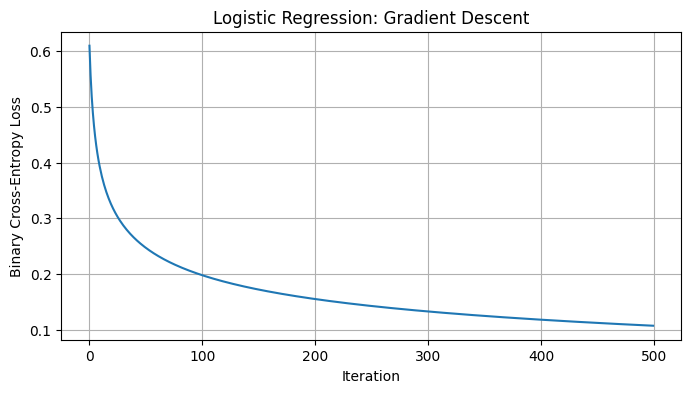

In [195]:

# Part 3: Logistic Regression using Log-Count Ratios

SEED = 42
np.random.seed(SEED)

# 1. Use the same top-2000 features selected in Part 2
features = list(vocab.keys())

# Get each feature's log ratio from Part 2
feature_log_ratios = np.array([
    log_ratios[feature] for feature in features
])

print("Number of features:", len(features))

# Show the most negative and positive log-ratio features
order = np.argsort(feature_log_ratios)

print("Most negative features:",
      [(features[j], round(feature_log_ratios[j], 4))
       for j in order[:10]])

print("Most positive features:",
      [(features[j], round(feature_log_ratios[j], 4))
       for j in order[::-1][:10]])

# 2. Build the training and test matrices
# Use the same train/test reviews from Part 1
train_reviews = train_pos + train_neg
test_reviews = test_pos + test_neg

y_train = np.array(
    [1] * len(train_pos) + [0] * len(train_neg)
)

y_test = np.array(
    [1] * len(test_pos) + [0] * len(test_neg)
)

X_train, mu, sigma = build_feature_matrix(
    train_reviews, features, feature_log_ratios
)

# Use training mean and standard deviation for test data
X_test, _, _ = build_feature_matrix(
    test_reviews, features, feature_log_ratios, mu, sigma
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# 3. Shuffle training rows
perm = np.random.RandomState(SEED).permutation(len(y_train))
X_train = X_train[perm]
y_train = y_train[perm]

# 4. Train Logistic Regression using Gradient Descent
model = LogisticRegression(
    lr=0.1,
    n_iters=500,
    l2=0.0,
    verbose=True
)

model.fit(X_train, y_train)

# 5. Evaluate the model
print("\nTrain accuracy:", round(model.score(X_train, y_train), 4))
print("Test accuracy:", round(model.score(X_test, y_test), 4))

# 6. Plot the loss curve
plt.figure(figsize=(8, 4))
plt.plot(model.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression: Gradient Descent")
plt.grid(True)
plt.show()


## Evaluation

In [197]:
def evaluate_lr(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return accuracy, precision, recall, f1_score

# 7. Evaluate Logistic Regression on the test set
y_pred = model.predict(X_test)
lr_acc, lr_prec, lr_rec, lr_f1 = evaluate_lr(y_test, y_pred)

print("\nLogistic Regression on test reviews")
print(f"Accuracy : {lr_acc:.4f}")
print(f"Precision: {lr_prec:.4f}")
print(f"Recall   : {lr_rec:.4f}")
print(f"F1 Score : {lr_f1:.4f}")



Logistic Regression on test reviews
Accuracy : 0.8330
Precision: 0.8297
Recall   : 0.8380
F1 Score : 0.8338


In [200]:
# 8. Compare all three models

import pandas as pd
from IPython.display import display

comparison = pd.DataFrame({
    "Model": [
        "Bigram Language Model",
        "Naive Bayes (Log-Ratio)",
        "Logistic Regression"
    ],
    "Input Representation": [
        "Word bigram probabilities",
        "Unigram features with log-count ratios",
        "Standardized unigram features weighted by log ratios"
    ],
    "Accuracy": [0.8760, 0.7980, 0.8330],
    "F1 Score": [0.8727, 0.7710, 0.8338]
})

metrics = ["Accuracy", "F1 Score"]

def bold_best(col):
    """Bold + teal text for the best value in each metric column."""
    return [
        "font-weight: 700; color: #0f766e;" if v == col.max() else ""
        for v in col
    ]

styled = (
    comparison.style
    .hide(axis="index")
    .format({m: "{:.4f}" for m in metrics})
    .bar(subset=metrics, color="#bfdbfe", vmin=0.5, vmax=1.0, width=90)
    .apply(bold_best, subset=metrics)
    .set_properties(subset=["Model"], **{
        "text-align": "left", "font-weight": "600", "color": "#0f172a"
    })
    .set_properties(subset=["Input Representation"], **{
        "text-align": "left", "color": "#475569"
    })
    .set_caption("Model Comparison on the Test Set")
    .set_table_styles([
        {"selector": "", "props": [
            ("border-collapse", "separate"),
            ("border-spacing", "0"),
            ("font-family", "'Segoe UI', Helvetica, Arial, sans-serif"),
            ("font-size", "14px"),
            ("border", "1px solid #e2e8f0"),
            ("border-radius", "10px"),
            ("overflow", "hidden"),
            ("box-shadow", "0 2px 8px rgba(15, 23, 42, 0.08)"),
        ]},
        {"selector": "caption", "props": [
            ("caption-side", "top"),
            ("text-align", "left"),
            ("font-size", "18px"),
            ("font-weight", "700"),
            ("color", "#0f172a"),
            ("padding", "0 0 10px 2px"),
        ]},
        {"selector": "th", "props": [
            ("background-color", "#1e293b"),
            ("color", "#ffffff"),
            ("text-align", "center"),
            ("font-weight", "600"),
            ("letter-spacing", "0.3px"),
            ("padding", "12px 18px"),
        ]},
        {"selector": "td", "props": [
            ("text-align", "center"),
            ("padding", "12px 18px"),
            ("color", "#1f2937"),
            ("background-color", "#ffffff"),
            ("border-bottom", "1px solid #e2e8f0"),
        ]},
        {"selector": "tbody tr:last-child td", "props": [
            ("border-bottom", "none"),
        ]},
        {"selector": "tbody tr:hover td", "props": [
            ("background-color", "#f1f5f9"),
        ]},
    ])
)

display(styled)

Model,Input Representation,Accuracy,F1 Score
Bigram Language Model,Word bigram probabilities,0.8760,0.8727
Naive Bayes (Log-Ratio),Unigram features with log-count ratios,0.7980,0.7710
Logistic Regression,Standardized unigram features weighted by log ratios,0.8330,0.8338



## Model Comparison and Discussion

The three models approach sentiment classification differently:

- **Bigram Language Model:** Uses the probability of consecutive words to
  estimate how likely a review is under the positive and negative language
  models. It captures local word order and some contextual information.

- **Naive Bayes:** Uses word features and their class-specific log-count
  ratios to determine whether a review is positive or negative. It is
  computationally efficient, but its performance depends on the quality of
  the selected features and probability estimates.

- **Logistic Regression:** Uses a weighted feature vector and learns feature
  weights through gradient descent. It combines evidence from multiple
  features to make a binary prediction.

### Results

The Bigram Language Model achieved **0.8760 accuracy** and **0.8727 F1
score**, while Naive Bayes achieved **0.7980 accuracy** and **0.7710 F1
score** on the test set. Logistic Regression should be compared using the
results reported in the table above.

Accuracy measures the proportion of correct predictions, whereas the F1
score balances precision and recall. Considering both metrics provides a
more complete evaluation of sentiment classification performance.

### Why might the models perform differently?

The Bigram Language Model can capture short word sequences that convey
sentiment, such as "not good" or "very bad". Naive Bayes relies on its
feature probabilities and may be less effective when its features fail to
capture useful context. Logistic Regression can learn discriminative
weights for different features, potentially improving classification by
combining their contributions.

The best-performing model is the one with the highest test performance,
considering both accuracy and F1 score. The observed differences may result
from the input representation, feature selection, model assumptions, and
training procedure.
